# Phase 7 : détection et comparaison (Q3, Q4, Q5)

Ce notebook construit un score de risque de 0 à 100 pour chaque transaction, le valide, compare les transactions signalées aux autres et produit la liste priorisée. Les fonctions sont dans `src/detection.py` et `src/comparisons.py`. Chaque étape est expliquée dans `docs/`.

Deux variantes :

- **sans étiquettes** (P7-01 à P7-07) : règles métier et anomalies. Les étiquettes de fraude ne servent à rien dans cette partie ;
- **avec étiquettes** (P7-08 et P7-11) : modèle supervisé, puis évaluation du score avec les étiquettes de fraude (`fraud_labels.json`, 67 % des transactions, P2-17).

## Chargement des données

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from src.load_data import load_clean_table
from src.charte import apply_style, save_figure, BLUE, ORANGE, NEUTRAL, TEXT_SECONDARY, THOUSANDS
from src.comparisons import rate_table, chi2_test, mann_whitney_test, holm_correction
from src.detection import (
    RULES, RULE_COLUMNS, rules_table, apply_rules, count_rules, BEHAVIOUR_FEATURES, behaviour_matrix,
    train_isolation_forest, anomaly_scores, risk_score, threshold_for_share, SHARES, threshold_summary,
    yearly_flag_rates, review_sample, main_reason, triggered_rules, ANOMALY_REASON, SHORT_LABELS, supervised_matrix,
    SUPERVISED_FEATURES, training_rows, train_supervised, precision_recall_at_shares,
    precision_recall_fixed_threshold, average_precision,
)

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
RESULTATS = Path("data/resultats")
RESULTATS.mkdir(parents=True, exist_ok=True)

In [2]:
colonnes = sorted(set(
    ["id", "date", "client_id", "card_id", "amount", "use_chip", "mcc", "mcc_family", "merchant_country",
     "merchant_city", "card_brand", "card_type", "has_chip", "gender",
     "age_at_transaction", "credit_score", "yearly_income", "total_debt", "credit_limit", "year", "weekday",
     "is_weekend", "client_median_amount", "is_fraud"]
    + RULE_COLUMNS + BEHAVIOUR_FEATURES[2:]
))
df = load_clean_table("analysis", columns=colonnes)
profils = load_clean_table("client_profiles", columns=["client_id", "profil_nom"])
df["profil_nom"] = df["client_id"].map(profils.set_index("client_id")["profil_nom"]).astype("category")
CANAUX = {"Swipe Transaction": "Bande magnétique", "Chip Transaction": "Puce", "Online Transaction": "En ligne"}
df["canal"] = df["use_chip"].map(CANAUX).astype("category")
codes_lieu = np.where(df["is_online"] == 1, 0, np.where(df["is_foreign"] == 1, 1, 2)).astype("int8")
df["lieu"] = pd.Categorical.from_codes(codes_lieu, ["En ligne", "À l'étranger", "Sur place aux États-Unis"])
print(f"{len(df):,} transactions, {df.shape[1]} colonnes, {df.memory_usage(deep=True).sum() / 1e6:,.0f} Mo")

13,305,915 transactions, 43 colonnes, 1,239 Mo


## P7-01 : coder les règles métier

Une règle par signal du catalogue des indicateurs (P4-09). Chaque règle donne des points : 3 pour un signal fort, 2 pour un signal moyen, 1 pour un signal faible, trop fréquent pour compter seul. Les seuils sont fixés à partir des distributions de la phase 4, sans regarder les étiquettes de fraude.

Critère de fin : règles codées et comptées. Voir `docs/P7-01_regles_metier.md`.

In [3]:
rules_table()

,règle,points,condition
code,,,
R01,2 échecs d'authentification ou plus sur la carte en 24 h,3,card_auth_errors_24h >= 2
R02,échec d'authentification sur la transaction,2,has_auth_error == 1
R03,montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),3,amount_ratio >= 20 and amount >= 300
R04,rafale : 5 transactions ou plus de la carte dans l'heure précédente,3,card_tx_1h >= 5
R05,15 transactions ou plus de la carte dans les 24 heures précédentes,2,card_tx_24h >= 15
R06,premier achat du client dans ce pays (après 100 transactions),2,is_first_country == 1 and client_tx_rank >= 100
R07,achat sur place à l'étranger,2,is_foreign == 1
R08,nouveau commerçant dans une nouvelle catégorie (après 100 transactions),2,is_first_merchant == 1 and is_first_mcc == 1 and client_tx_rank >= 100
R09,achat de nuit (0 h à 5 h 59),1,is_night == 1


In [4]:
flags = apply_rules(df)
comptage = count_rules(flags)
print(f"Transactions touchées par au moins une règle : {int((flags['n_rules'] > 0).sum()):,}")
print(f"Transactions touchées par une règle à 3 points : "
      f"{int(flags[[r[0] for r in RULES if r[2] == 3]].max(axis=1).sum()):,}")
comptage

Transactions touchées par au moins une règle : 3,661,140
Transactions touchées par une règle à 3 points : 76,369


,règle,points,transactions touchées,part_%
code,,,,
R01,2 échecs d'authentification ou plus sur la carte en 24 h,3,1602,0.012
R02,échec d'authentification sur la transaction,2,53977,0.406
R03,montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),3,41570,0.312
R04,rafale : 5 transactions ou plus de la carte dans l'heure précédente,3,32978,0.248
R05,15 transactions ou plus de la carte dans les 24 heures précédentes,2,13082,0.098
R06,premier achat du client dans ce pays (après 100 transactions),2,4135,0.031
R07,achat sur place à l'étranger,2,89006,0.669
R08,nouveau commerçant dans une nouvelle catégorie (après 100 transactions),2,67568,0.508
R09,achat de nuit (0 h à 5 h 59),1,770383,5.790


In [5]:
flags["rule_points"].clip(upper=8).value_counts().sort_index().rename("transactions (8 = 8 points ou plus)")

0    9644775
1    3173967
2     339657
3     100029
4      29763
5      11422
6       5015
7        820
8        467
Name: transactions (8 = 8 points ou plus), dtype: int64

**Constats**

- Les 13 règles sont codées : 4 à 3 points, 6 à 2 points et 3 à 1 point. Chaque règle correspond à un signal du catalogue (P4-09).
- La règle des échecs d'authentification est fixée à 2 échecs ou plus en 24 heures (1 602 transactions) : avec 3 échecs, comme dans l'exemple de Jira, elle ne toucherait que 22 transactions (P4-06).
- Les règles à 3 points restent rares : de 392 transactions (hors validité de la carte) à 41 570 (montant au moins 20 fois plus élevé que d'habitude). Ensemble, elles touchent 76 369 transactions.
- Les règles à 1 point sont fréquentes : achat en ligne (11,752 %), montant rond (10,146 %), achat de nuit (5,790 %). Seules, elles ne suffisent pas à signaler une transaction.
- 3 661 140 transactions déclenchent au moins une règle. 9 644 775 n'en déclenchent aucune, et 467 cumulent 8 points ou plus.

## P7-02 : détecter les anomalies avec Isolation Forest

Isolation Forest isole chaque transaction par des coupes au hasard : une transaction atypique est isolée en peu de coupes. Le modèle apprend sur un échantillon de 500 000 transactions (la mémoire ne permet pas tout d'un coup), puis donne un score d'anomalie à toutes les transactions.

Variables de comportement : montant et rapport au montant habituel (en logarithme), activité de la carte dans l'heure et dans les 24 heures, échecs d'authentification, heure, achat en ligne ou à l'étranger, premières fois, échec sur la transaction.

Critère de fin : score calculé pour toutes les transactions. Voir `docs/P7-02_isolation_forest.md`.

In [6]:
x = behaviour_matrix(df)
debut = time.perf_counter()
modele_if = train_isolation_forest(x)
anomalie = anomaly_scores(modele_if, x)
print(f"Apprentissage et calcul : {time.perf_counter() - debut:.0f} s")
print(f"Scores calculés : {len(anomalie):,} sur {len(df):,} transactions ; valeurs vides : {int(np.isnan(anomalie).sum())}")
print("Critère de fin validé :", len(anomalie) == len(df) and not np.isnan(anomalie).any())
pd.Series(anomalie).describe(percentiles=[0.5, 0.99, 0.999]).round(4)

Apprentissage et calcul : 88 s
Scores calculés : 13,305,915 sur 13,305,915 transactions ; valeurs vides : 0
Critère de fin validé : True


count    1.330592e+07
mean     4.054000e-01
std      6.090000e-02
min      3.390000e-01
50%      3.829000e-01
99%      6.260000e-01
99.9%    6.877000e-01
max      7.907000e-01
dtype: float64

In [7]:
# Profil des 1 % de transactions les plus atypiques selon Isolation Forest, comparé aux autres
atypiques = anomalie >= np.quantile(anomalie, 0.99)
somme_toutes = x.sum(axis=0, dtype=np.float64)
somme_atypiques = x[atypiques].sum(axis=0, dtype=np.float64)
n_atypiques = int(atypiques.sum())
comparaison_if = pd.DataFrame({
    "1 % les plus atypiques": somme_atypiques / n_atypiques,
    "autres transactions": (somme_toutes - somme_atypiques) / (len(x) - n_atypiques),
}, index=BEHAVIOUR_FEATURES).round(3)
del x
comparaison_if

,1 % les plus atypiques,autres transactions
log_amount,3.773,2.900
log_amount_ratio,0.867,-0.147
card_tx_1h,0.825,0.270
card_tx_24h,3.853,1.891
card_auth_errors_24h,0.138,0.008
hour,12.971,12.384
is_online,0.200,0.117
is_foreign,0.078,0.006
is_first_merchant,0.767,0.019
is_first_mcc,0.679,0.000


**Constats**

- Isolation Forest apprend sur 500 000 transactions et note les 13 305 915 transactions en 88 s, sans valeur vide : le critère de fin est validé.
- Le score d'anomalie a une médiane de 0,3829. Il vaut 0,6260 au quantile 99 %, et 0,7907 au maximum.
- Le 1 % de transactions les plus atypiques se distingue surtout par les premières fois : 0,767 sont un premier achat chez ce commerçant (contre 0,019 pour les autres) et 0,679 dans une nouvelle catégorie (contre 0,000).
- Elles ont aussi un montant plus élevé et plus éloigné du montant habituel, plus d'activité sur la carte (3,853 transactions en 24 heures contre 1,891) et plus d'achats à l'étranger (0,078 contre 0,006).

## P7-03 : construire le score de risque

Le score combine les deux approches, à parts égales :

- **partie règles** : points des règles déclenchées, plafonnés à 8, ramenés entre 0 et 1 ;
- **partie anomalies** : rang de la transaction selon le score d'Isolation Forest, entre 0 et 1.

Score = 100 × (0,5 × partie règles + 0,5 × partie anomalies). Seuil de signalement retenu : le 1 % le plus risqué.

Critère de fin : score et seuil documentés. Voir `docs/P7-03_score_risque.md`.

In [8]:
df["rule_points"] = flags["rule_points"].to_numpy()
df["anomaly_pct"] = pd.Series(anomalie).rank(pct=True).to_numpy().astype("float32")
df["risk_score"] = risk_score(df["rule_points"], anomalie)
seuils = {share: threshold_for_share(df["risk_score"], share) for share in SHARES}
seuil_1 = seuils[0.01]
df["signalee"] = (df["risk_score"] >= seuil_1).astype("int8")
print(f"Seuil retenu (1 % le plus risqué) : score de {seuil_1:.2f} ou plus")
print(f"Transactions signalées : {int(df['signalee'].sum()):,}")
df["risk_score"].describe(percentiles=[0.5, 0.9, 0.99, 0.995, 0.999]).round(2)

Seuil retenu (1 % le plus risqué) : score de 62.42 ou plus
Transactions signalées : 133,075


count    13305915.00
mean           27.05
std            16.47
min             0.00
50%            26.04
90%            48.61
99%            62.42
99.5%          68.42
99.9%          81.11
max           100.00
Name: risk_score, dtype: float64

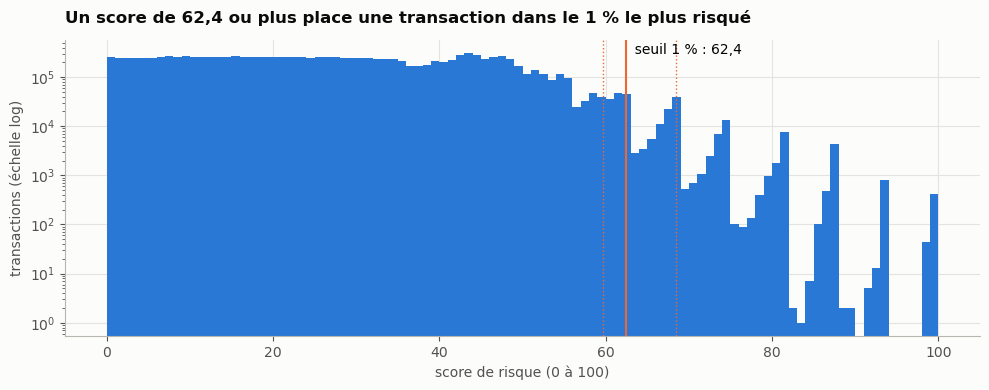

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df["risk_score"], bins=100, color=BLUE)
ax.set_yscale("log")
for share, couleur in zip(SHARES, [ORANGE, ORANGE, ORANGE]):
    ax.axvline(seuils[share], color=couleur, linewidth=1.5 if share == 0.01 else 1, linestyle="-" if share == 0.01 else ":")
ax.text(seuil_1, ax.get_ylim()[1] * 0.5, f"  seuil 1 % : {seuil_1:.1f}".replace(".", ","), color="black")
ax.set_xlabel("score de risque (0 à 100)")
ax.set_ylabel("transactions (échelle log)")
ax.set_title('Un score de 62,4 ou plus place une transaction dans le 1 % le plus risqué')
fig.tight_layout()
save_figure(fig, "P7-03_score_risque")
plt.show()

**Constats**

- Le seuil du 1 % le plus risqué est un score de 62,42. 133 075 transactions sont signalées.
- Le score médian est de 26,04. Il vaut 48,61 au quantile 90 %, 68,42 au quantile 99,5 % et 81,11 au quantile 99,9 %.
- La partie anomalies donne au plus 50 points : sans aucune règle déclenchée, une transaction ne peut pas atteindre le seuil.
- Le graphique montre des pics au-dessus du seuil : chacun correspond à un nombre de points de règles.